# Exp 3 — Analyse RNN+HN TaskDist training logs

Plot TensorBoard scalars from `hyper/logs` for GridNavi TaskDist runs (dense distance reward).

**Recall:** `Meta-Episode Return` = sum of `max_rollouts_per_task` MDP episode returns (default 4).

In [1]:
%matplotlib inline

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

CODE_DIR = Path.cwd().parent if Path.cwd().name == "scripts" else Path.cwd()
LOG_ROOT = CODE_DIR / "hyper" / "logs"

print("CODE_DIR:", CODE_DIR)
print("LOG_ROOT:", LOG_ROOT, "exists:", LOG_ROOT.exists())

CODE_DIR: /Users/maheshgondi/Documents/IITM/7/Adv_RL/hypex
LOG_ROOT: /Users/maheshgondi/Documents/IITM/7/Adv_RL/hypex/hyper/logs exists: True


In [2]:
def list_runs(log_root: Path = LOG_ROOT):
    """Find run dirs that contain a tfevents file."""
    runs = []
    if not log_root.exists():
        return runs
    for events in sorted(log_root.rglob("events.out.tfevents*")):
        runs.append(events.parent)
    return runs


def load_scalars(run_dir: Path):
    ea = EventAccumulator(str(run_dir), size_guidance={"scalars": 0})
    ea.Reload()
    tags = ea.Tags().get("scalars", [])
    out = {}
    for tag in tags:
        evs = ea.Scalars(tag)
        out[tag] = pd.DataFrame(
            {"step": [e.step for e in evs], "value": [e.value for e in evs]}
        )
    return out


def load_config(run_dir: Path):
    cfg_path = run_dir / "config.json"
    if not cfg_path.exists():
        return {}
    with open(cfg_path) as f:
        return json.load(f)


def smooth(y, window=21):
    if window is None or window <= 1 or len(y) < window:
        return np.asarray(y, dtype=float)
    w = np.ones(window) / window
    return np.convolve(y, w, mode="same")


runs = list_runs()
for i, r in enumerate(runs):
    cfg = load_config(r)
    print(f"[{i}] {r.relative_to(LOG_ROOT)}")
    print(f"     env={cfg.get('env_name')}  label={cfg.get('exp_label')}  seed={cfg.get('seed')}")

[0] logs_GridNavi-TaskDist1-v0/RNN+HN_taskdist1_73__14:09_13:14:38_25d58
     env=GridNavi-TaskDist1-v0  label=RNN+HN_taskdist1  seed=73
[1] logs_GridNavi-TaskDist1-v0/RNN+HN_taskdist1_73__14:09_13:20:20_29dd5
     env=GridNavi-TaskDist1-v0  label=RNN+HN_taskdist1  seed=73


In [3]:
# Pick the run to analyse (prefer the longest / latest TaskDist1 run)
RUN_IDX = None  # set explicitly, or leave None to auto-pick

if RUN_IDX is None:
    candidates = [r for r in runs if "TaskDist1" in str(r)]
    if not candidates:
        candidates = runs
    # prefer run with most scalar points on Meta-Episode Return
    best, best_n = None, -1
    for r in candidates:
        sc = load_scalars(r)
        n = len(sc.get("Meta-Episode Return", []))
        if n > best_n:
            best, best_n = r, n
    RUN_DIR = best
else:
    RUN_DIR = runs[RUN_IDX]

cfg = load_config(RUN_DIR)
scalars = load_scalars(RUN_DIR)
print("Selected:", RUN_DIR)
print("Scalar tags:", len(scalars))
print("num_frames:", cfg.get("num_frames"))
print("max_rollouts_per_task:", cfg.get("max_rollouts_per_task"))
print("policy_num_steps:", cfg.get("policy_num_steps"))
print("num_processes:", cfg.get("num_processes"))
print("use_hypernet:", cfg.get("use_hypernet"), "hypernet_input:", cfg.get("hypernet_input"))

Selected: /Users/maheshgondi/Documents/IITM/7/Adv_RL/hypex/hyper/logs/logs_GridNavi-TaskDist1-v0/RNN+HN_taskdist1_73__14:09_13:20:20_29dd5
Scalar tags: 40
num_frames: 4000000
max_rollouts_per_task: 4
policy_num_steps: 60
num_processes: 4
use_hypernet: True hypernet_input: latent


## Returns vs frames

Per-episode curves are MDP returns (15 steps). Meta-episode is their sum across rollouts.

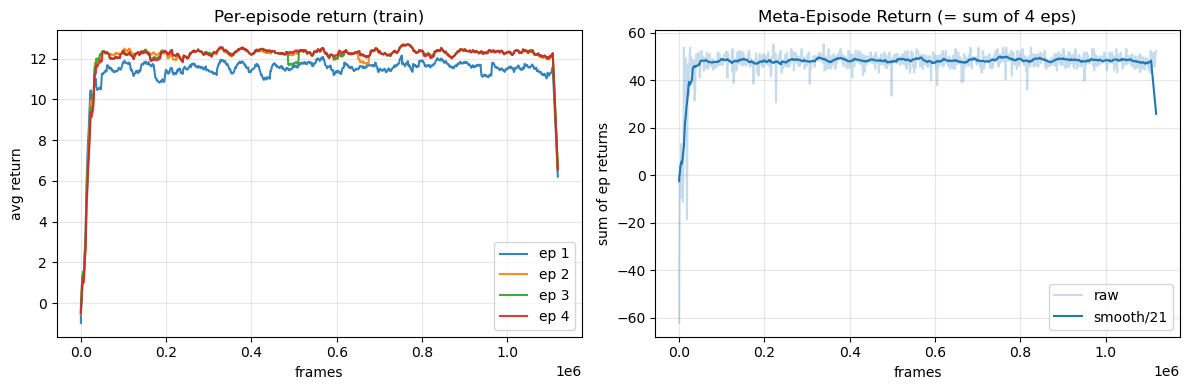

In [4]:
K = int(cfg.get("max_rollouts_per_task", 4))
SMOOTH = 21

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)

# per-episode returns
ax = axes[0]
for k in range(1, K + 1):
    tag = f"return_avg_per_frame/episode_{k}"
    if tag not in scalars:
        continue
    df = scalars[tag]
    ax.plot(df["step"], smooth(df["value"], SMOOTH), label=f"ep {k}", alpha=0.9)
ax.set_xlabel("frames")
ax.set_ylabel("avg return")
ax.set_title("Per-episode return (train)")
ax.legend()
ax.grid(True, alpha=0.3)

# meta-episode
ax = axes[1]
tag = "Meta-Episode Return"
if tag in scalars:
    df = scalars[tag]
    ax.plot(df["step"], df["value"], alpha=0.25, color="C0", label="raw")
    ax.plot(df["step"], smooth(df["value"], SMOOTH), color="C0", label=f"smooth/{SMOOTH}")
ax.set_xlabel("frames")
ax.set_ylabel("sum of ep returns")
ax.set_title(f"Meta-Episode Return (= sum of {K} eps)")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [5]:
# Summary table: early / mid / late returns
def window_stats(df, lo, hi):
    m = (df["step"] >= lo) & (df["step"] <= hi)
    v = df.loc[m, "value"]
    if len(v) == 0:
        return np.nan, np.nan, 0
    return float(v.mean()), float(v.std()), int(len(v))

max_frame = int(scalars["Meta-Episode Return"]["step"].max()) if "Meta-Episode Return" in scalars else 0
windows = [
    ("early", 0, max(50_000, max_frame // 20)),
    ("~200k", 150_000, 250_000),
    ("late", max(0, max_frame - 100_000), max_frame),
]

rows = []
tags = [f"return_avg_per_frame/episode_{k}" for k in range(1, K + 1)] + ["Meta-Episode Return"]
for tag in tags:
    if tag not in scalars:
        continue
    df = scalars[tag]
    row = {"tag": tag}
    for name, lo, hi in windows:
        mu, sd, n = window_stats(df, lo, hi)
        row[f"{name}_mean"] = mu
        row[f"{name}_std"] = sd
        row[f"{name}_n"] = n
    rows.append(row)

summary = pd.DataFrame(rows)
display(summary.round(2))
print(f"max logged frame: {max_frame:,}")

,tag,early_mean,early_std,early_n,~200k_mean,~200k_std,~200k_n,late_mean,late_std,late_n
0,return_avg_per_frame/episode_1,7.67,6.96,48,11.34,1.19,84,11.48,0.95,84
1,return_avg_per_frame/episode_2,8.11,6.84,48,12.16,0.84,84,12.24,0.61,84
2,return_avg_per_frame/episode_3,8.05,6.76,48,12.17,0.88,84,12.26,0.59,84
3,return_avg_per_frame/episode_4,7.78,6.81,48,12.13,0.93,84,12.26,0.58,84
4,Meta-Episode Return,31.60,26.69,48,47.79,3.22,84,48.24,2.46,84


max logged frame: 1,118,640


## Optimal return ceiling (TaskDist1, distance reward)

Env used here: `num_cells=5`, `num_steps=15`, start `(2,2)`, goals from TaskDist1.
Distance reward while off-goal; `+1` each step on the goal; episode does **not** terminate early.

In [6]:
def goal_positions(option, num_cells):
    if option == 1:
        return [(num_cells - 1, num_cells - 1), (num_cells - 1, num_cells - 2),
                (num_cells - 2, num_cells - 1), (num_cells - 2, num_cells - 2)]
    raise ValueError(option)


def optimal_return(start, goal, num_cells, max_steps):
    """Greedy shortest path then stay; matches GridNavi distance_reward."""
    pos = list(start)
    g = list(goal)
    total = 0.0
    for _ in range(max_steps):
        if pos[0] != g[0]:
            pos[0] += 1 if pos[0] < g[0] else -1
        elif pos[1] != g[1]:
            pos[1] += 1 if pos[1] < g[1] else -1
        if pos == g:
            total += 1.0
        else:
            total += -(abs(pos[0] - g[0]) + abs(pos[1] - g[1])) / num_cells
    return total


NUM_CELLS = 5
MAX_STEPS = 15
START = (2, 2)
goals = goal_positions(1, NUM_CELLS)
opts = [optimal_return(START, g, NUM_CELLS, MAX_STEPS) for g in goals]

opt_df = pd.DataFrame({"goal": goals, "manhattan": [abs(g[0]-START[0])+abs(g[1]-START[1]) for g in goals], "opt_return": opts})
display(opt_df)
print(f"mean optimal MDP return: {np.mean(opts):.2f}")
print(f"mean optimal Meta-Episode Return (x{K}): {K * np.mean(opts):.2f}")

if "Meta-Episode Return" in scalars:
    late = scalars["Meta-Episode Return"]
    late_vals = late.loc[late["step"] >= max(0, max_frame - 100_000), "value"]
    print(f"logged late Meta-Episode mean: {late_vals.mean():.2f}  (ceiling ≈ {K * np.mean(opts):.2f})")

,goal,manhattan,opt_return
0,"(4, 4)",4,10.8
1,"(4, 3)",3,12.4
2,"(3, 4)",3,12.4
3,"(3, 3)",2,13.8


mean optimal MDP return: 12.35
mean optimal Meta-Episode Return (x4): 49.40
logged late Meta-Episode mean: 48.24  (ceiling ≈ 49.40)


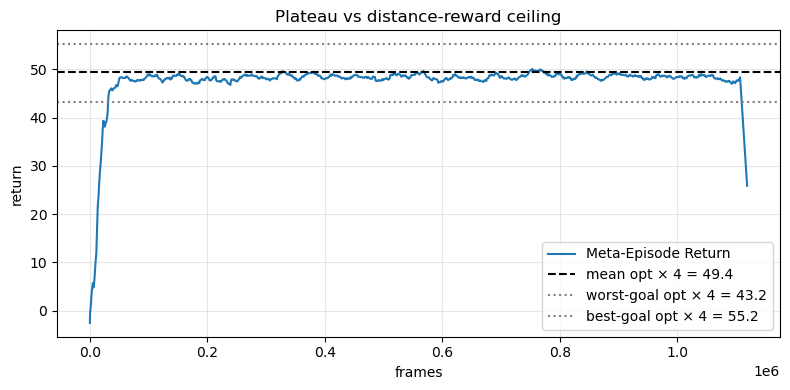

In [7]:
# Overlay empirical meta return vs theoretical mean ceiling
if "Meta-Episode Return" in scalars:
    df = scalars["Meta-Episode Return"]
    ceiling = K * np.mean(opts)
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(df["step"], smooth(df["value"], SMOOTH), label="Meta-Episode Return")
    ax.axhline(ceiling, color="k", ls="--", label=f"mean opt × {K} = {ceiling:.1f}")
    ax.axhline(K * min(opts), color="gray", ls=":", label=f"worst-goal opt × {K} = {K*min(opts):.1f}")
    ax.axhline(K * max(opts), color="gray", ls=":", label=f"best-goal opt × {K} = {K*max(opts):.1f}")
    ax.set_xlabel("frames")
    ax.set_ylabel("return")
    ax.set_title("Plateau vs distance-reward ceiling")
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## Policy losses / entropy / norms

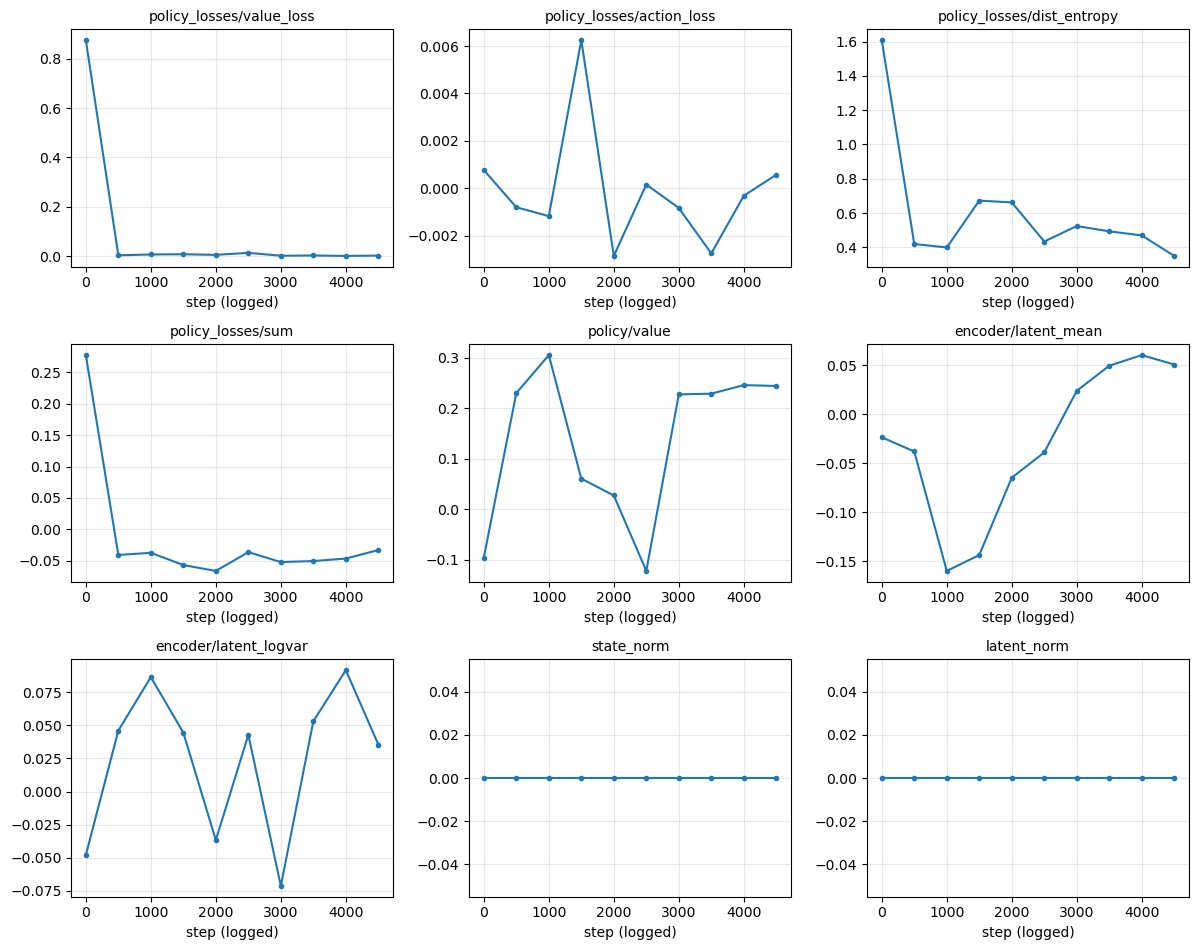

Note: policy_* tags are logged sparsely (e.g. every save_interval), while returns are denser.


In [8]:
loss_tags = [
    "policy_losses/value_loss",
    "policy_losses/action_loss",
    "policy_losses/dist_entropy",
    "policy_losses/sum",
    "policy/value",
    "encoder/latent_mean",
    "encoder/latent_logvar",
    "state_norm",
    "latent_norm",
]

present = [t for t in loss_tags if t in scalars]
ncols = 3
nrows = int(np.ceil(len(present) / ncols)) or 1
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.2 * nrows), squeeze=False)
for i, tag in enumerate(present):
    ax = axes[i // ncols][i % ncols]
    df = scalars[tag]
    ax.plot(df["step"], df["value"], marker="o", ms=3)
    ax.set_title(tag, fontsize=10)
    ax.set_xlabel("step (logged)")
    ax.grid(True, alpha=0.3)
for j in range(len(present), nrows * ncols):
    axes[j // ncols][j % ncols].axis("off")
plt.tight_layout()
plt.show()

print("Note: policy_* tags are logged sparsely (e.g. every save_interval), while returns are denser.")

## Saved latent visualisations

PNGs written during training (`{iter}_latents.png`).

found 10 latent plots in RNN+HN_taskdist1_73__14:09_13:20:20_29dd5
0_latents.png


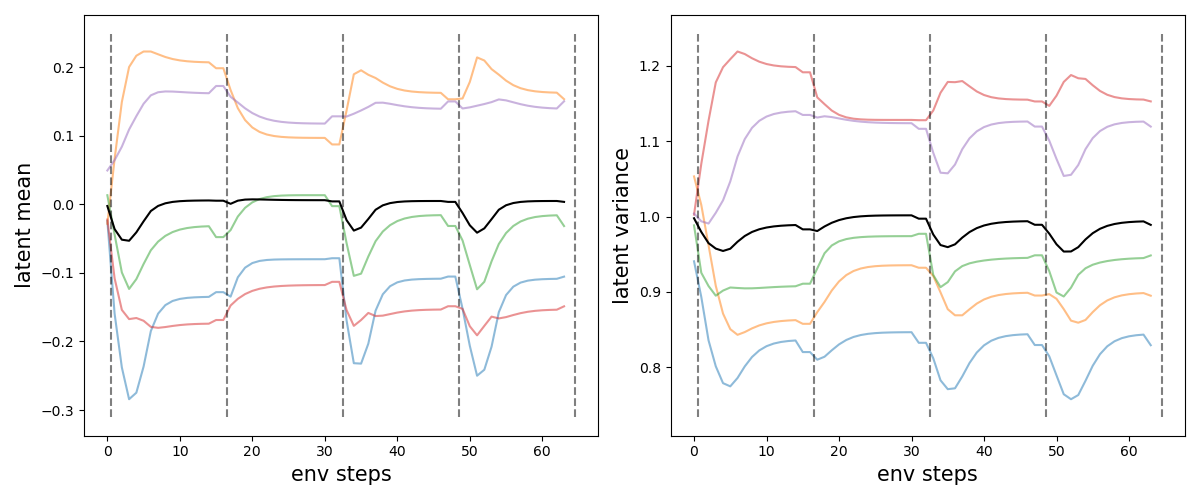

2500_latents.png


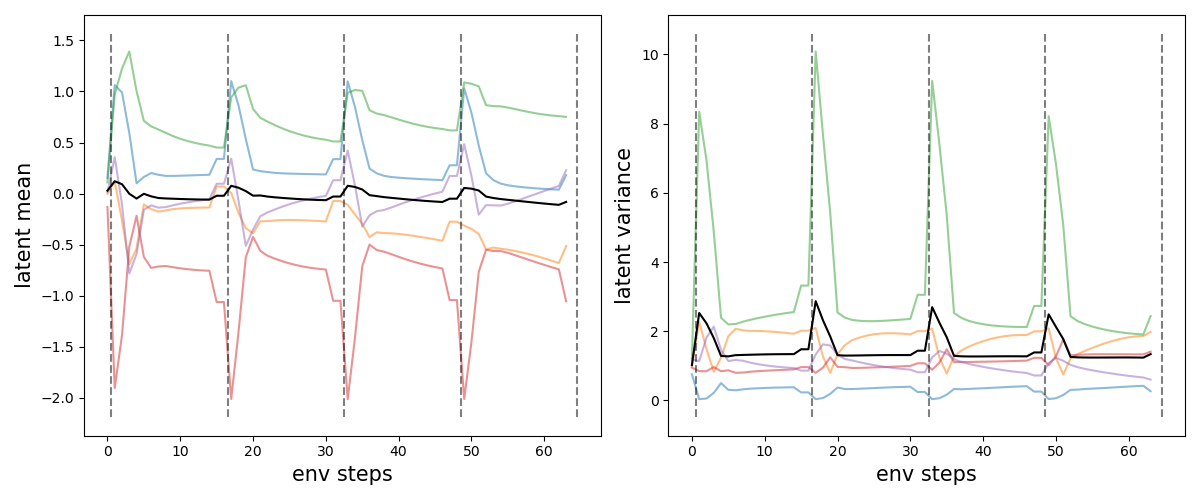

4500_latents.png


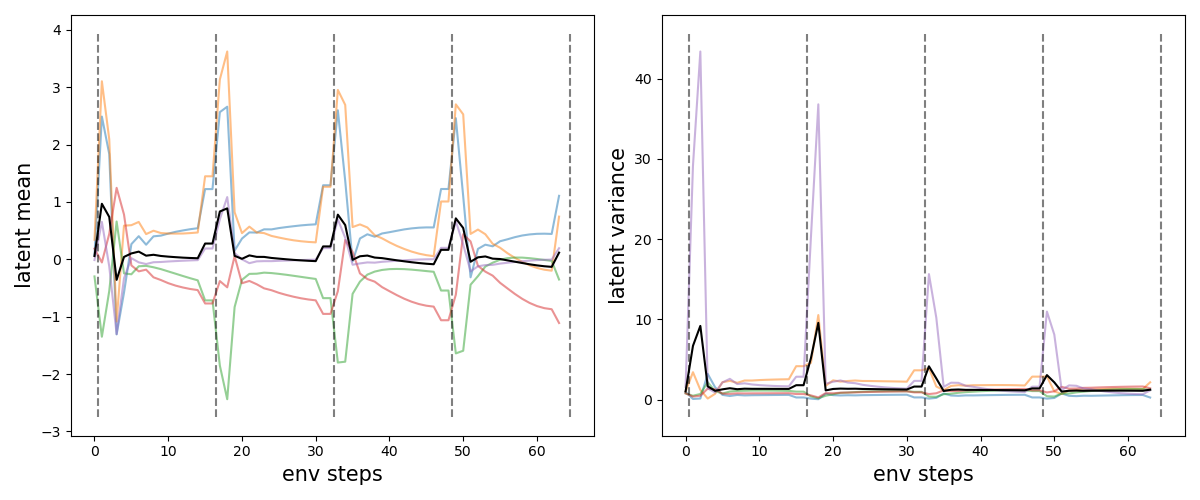

In [9]:
latent_pngs = sorted(RUN_DIR.glob("*_latents.png"), key=lambda p: int(p.stem.split("_")[0]))
print(f"found {len(latent_pngs)} latent plots in {RUN_DIR.name}")

# show a few: first, mid, last
show = []
if latent_pngs:
    idxs = sorted(set([0, len(latent_pngs) // 2, len(latent_pngs) - 1]))
    show = [latent_pngs[i] for i in idxs]

for p in show:
    print(p.name)
    display(Image(filename=str(p), width=480))

## Config snapshot (selected keys)

In [10]:
keys = [
    "env_name", "exp_label", "seed", "num_frames", "num_processes",
    "max_rollouts_per_task", "policy_num_steps", "policy_layers",
    "use_hypernet", "hypernet_input", "hypernet_head_bias", "policy_layers_hyper",
    "init_hyper_for_policy", "init_adjust_bias", "init_adjust_weights",
    "disable_decoder", "rlloss_through_encoder", "norm_latent_for_policy",
    "disable_stochasticity_in_latent", "encoder_gru_hidden_size",
    "policy_state_embedding_dim", "policy_latent_embedding_dim", "latent_dim",
]
snap = {k: cfg.get(k) for k in keys}
display(pd.Series(snap, name="value").to_frame())

,value
env_name,GridNavi-TaskDist1-v0
exp_label,RNN+HN_taskdist1
seed,73
num_frames,4000000
num_processes,4
max_rollouts_per_task,4
policy_num_steps,60
policy_layers,"[32, 32]"
use_hypernet,True
hypernet_input,latent


## Takeaways

- Per-episode returns climb from strongly negative to ~11–13, then flatten.
- Meta-Episode ~44–50 is **4 ×** that MDP return, not a different reward scale.
- Flattening matches the distance-reward **optimal ceiling** on 5×5 / 15 steps TaskDist1.
- `Meta-Episode Success` stays 0 because `GridNavi` does not set `info['success']`.